In [ ]:
import os
import fastf1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs("cache", exist_ok=True)
fastf1.Cache.enable_cache("cache")  # saves downloads so reruns are fast

In [3]:
schedule = fastf1.get_event_schedule(2026)
print(schedule[["RoundNumber", "EventName", "EventDate"]]) # find the latest round that has happened
ROUND = 16 # change to the most recent completed round
session = fastf1.get_session(2026, ROUND,"R") # "R" = race
session.load()
print(session.event["EventName"])

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.8.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...


    RoundNumber                 EventName  EventDate
0             0        Pre-Season Testing 2026-02-13
1             0        Pre-Season Testing 2026-02-20
2             1     Australian Grand Prix 2026-03-08
3             2        Chinese Grand Prix 2026-03-15
4             3       Japanese Grand Prix 2026-03-29
5             4          Miami Grand Prix 2026-05-03
6             5       Canadian Grand Prix 2026-05-24
7             6         Monaco Grand Prix 2026-06-07
8             7      Barcelona Grand Prix 2026-06-14
9             8       Austrian Grand Prix 2026-06-28
10            9        British Grand Prix 2026-07-05
11           10        Belgian Grand Prix 2026-07-19
12           11      Hungarian Grand Prix 2026-07-26
13           12          Dutch Grand Prix 2026-08-23
14           13        Italian Grand Prix 2026-09-06
15           14        Spanish Grand Prix 2026-09-13
16           15     Azerbaijan Grand Prix 2026-09-26
17           16        Bahrain Grand Prix 2026

req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for lap_count. Loading data...
_api           INFO 	Fetching lap count data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api           INFO 	Fetching timing data...
_api           INFO 	Parsing timing data...
req            INFO 	Data has been written to cache!

Bahrain Grand Prix


In [4]:
laps = session.laps.pick_drivers(['30', '41']) # check the codes insession.results if this is empty
print(len(laps), "laps before cleaning")

clean = (laps
         .pick_wo_box()            # remove in-laps and out-laps (pit stops)
         .pick_track_status("1")   # green flag only: no safety car, VSC or yellows
         .pick_quicklaps())        # drop laps much slower than the fastest (traffic, mistakes)

clean = clean[clean["LapNumber"] > 1]   # lap 1 is a standing start, not representative
clean = pd.DataFrame(clean)             # plain DataFrame for easy maths
clean["LapTime_s"] = clean["LapTime"].dt.total_seconds()  # timedelta -> seconds

print(len(clean), "laps after cleaning")
print(clean[["Driver", "LapNumber", "Stint", "Compound", "TyreLife", "LapTime_s"]].head())

110 laps before cleaning
59 laps after cleaning
    Driver  LapNumber  Stint Compound  TyreLife  LapTime_s
550    LAW       14.0    2.0     HARD       5.0    105.742
551    LAW       15.0    2.0     HARD       6.0    104.646
553    LAW       17.0    2.0     HARD       8.0    103.958
554    LAW       18.0    2.0     HARD       9.0    103.703
555    LAW       19.0    2.0     HARD      10.0    103.239


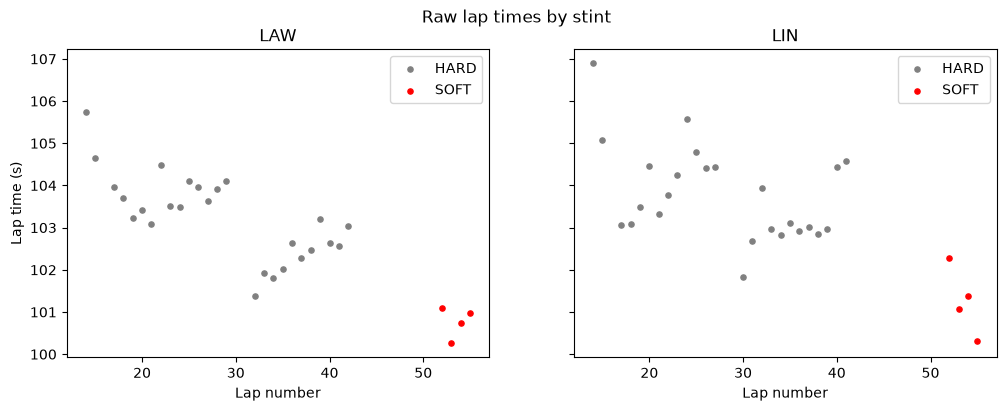

In [5]:
colors = {"SOFT": "red", "MEDIUM": "gold", "HARD": "gray"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, drv in zip(axes, ["LAW", "LIN"]):
    d = clean[clean["Driver"] == drv]
    for comp, g in d.groupby("Compound"):
        ax.scatter(g["LapNumber"], g["LapTime_s"], s=14,
                   color=colors.get(comp, "blue"), label=comp)
    ax.set_title(drv)
    ax.set_xlabel("Lap number")
    ax.legend()

axes[0].set_ylabel("Lap time (s)")
plt.suptitle("Raw lap times by stint")
plt.show()

In [11]:
K_FUEL = 0.03  # ASSUMPTION: seconds gained per lap as fuel burns off
clean["LapTime_fc"] = clean["LapTime_s"] + K_FUEL * (clean["LapNumber"] - 1)
clean = clean.dropna(subset=["LapTime_s", "TyreLife"])  # drop laps with missing data

In [12]:
results = []
for (drv, stint), g in clean.groupby(["Driver", "Stint"]):
    if len(g) < 6:
        continue  # too few laps to trust a slope
    fit = stats.linregress(g["TyreLife"], g["LapTime_fc"])
    results.append({
        "Driver": drv,
        "Stint": int(stint),
        "Compound": g["Compound"].iloc[0],
        "Laps": len(g),
        "Deg_s_per_lap": round(fit.slope, 3),
        "Low_95": round(fit.slope - 2 * fit.stderr, 3),
        "High_95": round(fit.slope + 2 * fit.stderr, 3),
        "R2": round(fit.rvalue ** 2, 2),
    })

deg = pd.DataFrame(results)
print(deg)

  Driver  Stint Compound  Laps  Deg_s_per_lap  Low_95  High_95    R2
0    LAW      2     HARD    15         -0.021  -0.094    0.051  0.03
1    LIN      2     HARD    13          0.000  -0.157    0.157  0.00
2    LIN      3     HARD    12          0.166   0.060    0.272  0.50


In [13]:
for k in [0.02, 0.03, 0.04]:
    slopes = {}
    for (drv, stint), g in clean.groupby(["Driver", "Stint"]):
        if len(g) < 6:
            continue
        t = g["LapTime_s"] + k * (g["LapNumber"] - 1)
        slopes[f"{drv} stint {int(stint)}"] = round(stats.linregress(g["TyreLife"], t).slope, 3)
    print(f"K_FUEL={k}:", slopes)

K_FUEL=0.02: {'LAW stint 2': np.float64(-0.031), 'LIN stint 2': np.float64(-0.01), 'LIN stint 3': np.float64(0.156)}
K_FUEL=0.03: {'LAW stint 2': np.float64(-0.021), 'LIN stint 2': np.float64(0.0), 'LIN stint 3': np.float64(0.166)}
K_FUEL=0.04: {'LAW stint 2': np.float64(-0.011), 'LIN stint 2': np.float64(0.01), 'LIN stint 3': np.float64(0.176)}


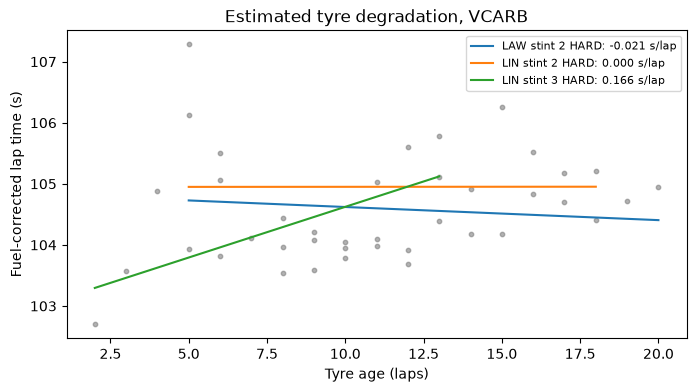

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
for (drv, stint), g in clean.groupby(["Driver", "Stint"]):
    if len(g) < 6:
        continue
    fit = stats.linregress(g["TyreLife"], g["LapTime_fc"])
    comp = g["Compound"].iloc[0]
    ax.scatter(g["TyreLife"], g["LapTime_fc"], s=10,
               color=colors.get(comp, "blue"), alpha=0.6)
    x = np.array([g["TyreLife"].min(), g["TyreLife"].max()])
    ax.plot(x, fit.intercept + fit.slope * x,
            label=f"{drv} stint {int(stint)} {comp}: {fit.slope:.3f} s/lap")

ax.set_xlabel("Tyre age (laps)")
ax.set_ylabel("Fuel-corrected lap time (s)")
ax.set_title("Estimated tyre degradation, VCARB")
ax.legend(fontsize=8)
plt.show()

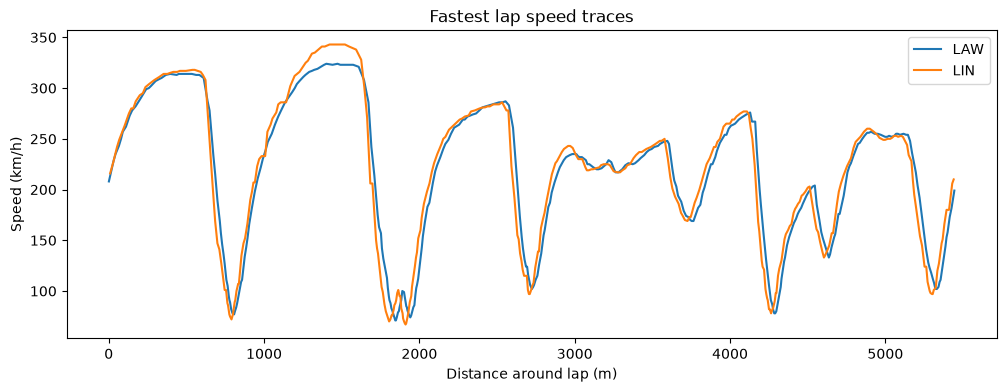

In [15]:
lap_law = session.laps.pick_drivers("30").pick_fastest()
lap_lin = session.laps.pick_drivers("41").pick_fastest()
tel_law = lap_law.get_car_data().add_distance()
tel_lin = lap_lin.get_car_data().add_distance()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(tel_law["Distance"], tel_law["Speed"], label="LAW")
ax.plot(tel_lin["Distance"], tel_lin["Speed"], label="LIN")
ax.set_xlabel("Distance around lap (m)")
ax.set_ylabel("Speed (km/h)")
ax.set_title("Fastest lap speed traces")
ax.legend()
plt.show()

**Question:** how quickly did VCARB's tyres degrade at the 2026 Bahrain Grand Prix?

**Method:** same as Singapore. Removed pit, safety car, lap 1 and traffic laps. Added back an assumed 0.03 s per lap fuel effect. Fitted a straight line of lap time vs tyre age for each stint.

**Findings:**
1. Only 59 of 110 laps survived cleaning, and neither driver's first stint was usable, so this race gives much less to work with than Singapore.
2. On the first hard stint, neither driver showed measurable wear (both ranges include zero).
3. Lindblad's second hard stint showed about 0.17 s per lap (range 0.06 to 0.27), but most of that comes from his last two laps before pitting. That could be a tyre cliff or traffic; 12 laps isn't enough to tell. Lawson's second hard stint: [fill in after rerun].
4. The fuel assumption again shifted every value by the same amount without changing the ranking.

**Limitations:** short stints, heavy lap scatter (often 1 to 2 s lap to lap), and too few soft-tyre laps to fit. Straight lines can't capture a cliff. One race only.